In [ ]:
import numpy as np
import pandas as pd

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving fastfood.csv to fastfood.csv


In [ ]:
df = pd.read_csv("fastfood.csv")
print("Dataset Preview:\n", df.head())

Dataset Preview:
   restaurant                                       item  calories  cal_fat  \
0  Mcdonalds           Artisan Grilled Chicken Sandwich       380       60   
1  Mcdonalds             Single Bacon Smokehouse Burger       840      410   
2  Mcdonalds             Double Bacon Smokehouse Burger      1130      600   
3  Mcdonalds  Grilled Bacon Smokehouse Chicken Sandwich       750      280   
4  Mcdonalds   Crispy Bacon Smokehouse Chicken Sandwich       920      410   

   total_fat  sat_fat  trans_fat  cholesterol  sodium  total_carb  fiber  \
0          7      2.0        0.0           95    1110          44    3.0   
1         45     17.0        1.5          130    1580          62    2.0   
2         67     27.0        3.0          220    1920          63    3.0   
3         31     10.0        0.5          155    1940          62    2.0   
4         45     12.0        0.5          120    1980          81    4.0   

   sugar  protein  vit_a  vit_c  calcium  salad  
0     

In [ ]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 515 entries, 0 to 514
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   restaurant   515 non-null    object 
 1   item         515 non-null    object 
 2   calories     515 non-null    int64  
 3   cal_fat      515 non-null    int64  
 4   total_fat    515 non-null    int64  
 5   sat_fat      515 non-null    float64
 6   trans_fat    515 non-null    float64
 7   cholesterol  515 non-null    int64  
 8   sodium       515 non-null    int64  
 9   total_carb   515 non-null    int64  
 10  fiber        503 non-null    float64
 11  sugar        515 non-null    int64  
 12  protein      514 non-null    float64
 13  vit_a        301 non-null    float64
 14  vit_c        305 non-null    float64
 15  calcium      305 non-null    float64
 16  salad        515 non-null    object 
dtypes: float64(7), int64(7), object(3)
memory usage: 68.5+ KB


In [ ]:
print("\nMissing Values:")
df.isnull().sum()


Missing Values:


,0
restaurant,0
item,0
calories,0
cal_fat,0
total_fat,0
sat_fat,0
trans_fat,0
cholesterol,0
sodium,0
total_carb,0


In [ ]:
# Impute missing values in 'fiber' and 'protein' with the mean
df['fiber'].fillna(df['fiber'].mean(), inplace=True)
df['protein'].fillna(df['protein'].mean(), inplace=True)

# Drop 'vit_a', 'vit_c', and 'calcium' columns due to high percentage of missing values
df.drop(columns=['vit_a', 'vit_c', 'calcium'], inplace=True)

print("\nMissing Values After Cleaning:")
df.isnull().sum()


Missing Values After Cleaning:


/tmp/ipykernel_1775/1075454556.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['fiber'].fillna(df['fiber'].mean(), inplace=True)
/tmp/ipykernel_1775/1075454556.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', 

,0
restaurant,0
item,0
calories,0
cal_fat,0
total_fat,0
sat_fat,0
trans_fat,0
cholesterol,0
sodium,0
total_carb,0


In [ ]:
print("\nDescriptive Statistics of Numerical Columns:")
print(df.describe())


Descriptive Statistics of Numerical Columns:
          calories      cal_fat   total_fat     sat_fat   trans_fat  \
count   515.000000   515.000000  515.000000  515.000000  515.000000   
mean    530.912621   238.813592   26.590291    8.153398    0.465049   
std     282.436147   166.407510   18.411876    6.418811    0.839644   
min      20.000000     0.000000    0.000000    0.000000    0.000000   
25%     330.000000   120.000000   14.000000    4.000000    0.000000   
50%     490.000000   210.000000   23.000000    7.000000    0.000000   
75%     690.000000   310.000000   35.000000   11.000000    1.000000   
max    2430.000000  1270.000000  141.000000   47.000000    8.000000   

       cholesterol       sodium  total_carb       fiber       sugar  \
count   515.000000   515.000000  515.000000  515.000000  515.000000   
mean     72.456311  1246.737864   45.664078    4.137177    7.262136   
std      63.160406   689.954278   24.883342    3.001794    6.761301   
min       0.000000    15.00000

In [ ]:
from sklearn.preprocessing import StandardScaler

# Identify numerical columns to scale (excluding 'restaurant', 'item', 'salad' as they are categorical or will be handled separately)
# Assuming all remaining columns are numerical after dropping 'vit_a', 'vit_c', 'calcium' and handling 'fiber', 'protein'
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

# Initialize StandardScaler
scaler = StandardScaler()

# Apply standardization to numerical columns
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

print("\nDescriptive Statistics of Scaled Numerical Columns:")
print(df[numerical_cols].describe())


Descriptive Statistics of Scaled Numerical Columns:
           calories       cal_fat     total_fat       sat_fat   trans_fat  \
count  5.150000e+02  5.150000e+02  5.150000e+02  5.150000e+02  515.000000   
mean   1.379695e-17  5.518779e-17  5.518779e-17 -9.657862e-17    0.000000   
std    1.000972e+00  1.000972e+00  1.000972e+00  1.000972e+00    1.000972   
min   -1.810708e+00 -1.436508e+00 -1.445597e+00 -1.271470e+00   -0.554403   
25%   -7.120476e-01 -7.146860e-01 -6.844785e-01 -6.476957e-01   -0.554403   
50%   -1.449970e-01 -1.733191e-01 -1.951883e-01 -1.798650e-01   -0.554403   
75%    5.638161e-01  4.281996e-01  4.571987e-01  4.439093e-01    0.637737   
max    6.730491e+00  6.202779e+00  6.219950e+00  6.057878e+00    8.982711   

        cholesterol        sodium    total_carb         fiber         sugar  \
count  5.150000e+02  5.150000e+02  5.150000e+02  5.150000e+02  5.150000e+02   
mean   5.518779e-17  1.379695e-17 -1.379695e-16  5.518779e-17 -6.898473e-17   
std    1.000972e

In [ ]:
# Identify categorical columns
categorical_cols = df.select_dtypes(include='object').columns.tolist()

print("\nCategorical Columns and their Unique Values/Counts:")
for col in categorical_cols:
    print(f"\nColumn '{col}':")
    print(df[col].value_counts())


Categorical Columns and their Unique Values/Counts:

Column 'restaurant':
restaurant
Taco Bell      115
Subway          96
Burger King     70
Mcdonalds       57
Arbys           55
Sonic           53
Dairy Queen     42
Chick Fil-A     27
Name: count, dtype: int64

Column 'item':
item
Crispy Chicken Sandwich              3
Grilled Chicken Sandwich             3
Chili Cheese Burrito                 2
Corn Dog                             2
Double Cheeseburger                  2
                                    ..
Reuben Sandwich                      1
5 piece Prime-Cut Chicken Tenders    1
3 piece Prime-Cut Chicken Tenders    1
2 piece Prime-Cut Chicken Tenders    1
Turkey Avocado Club                  1
Name: count, Length: 505, dtype: int64

Column 'salad':
salad
Other    515
Name: count, dtype: int64


In [ ]:
# Drop 'item' column due to high cardinality and 'salad' due to being a constant column
df.drop(columns=['item', 'salad'], inplace=True)

# Apply one-hot encoding to the 'restaurant' column
df = pd.get_dummies(df, columns=['restaurant'], prefix='restaurant')

print("\nDataFrame after handling categorical variables:")
print(df.head())


DataFrame after handling categorical variables:
   calories   cal_fat  total_fat   sat_fat  trans_fat  cholesterol    sodium  \
0 -0.534844 -1.075597  -1.065038 -0.959583  -0.554403     0.357275 -0.198377   
1  1.095426  1.029718   1.000854  1.379571   1.233806     0.911958  0.483490   
2  2.123205  2.172604   2.196897  2.939006   3.022015     2.338287  0.976756   
3  0.776460  0.247744   0.239736  0.287966   0.041667     1.308160  1.005771   
4  1.378951  1.029718   1.000854  0.599853   0.041667     0.753477  1.063802   

   total_carb     fiber    sugar   protein  restaurant_Arbys  \
0   -0.066940 -0.379201  0.55337  0.516101             False   
1    0.657139 -0.712659  1.58968  1.026029             False   
2    0.697365 -0.379201  1.58968  2.385837             False   
3    0.657139 -0.712659  1.58968  1.535957             False   
4    1.421444 -0.045743  1.58968  1.026029             False   

   restaurant_Burger King  restaurant_Chick Fil-A  restaurant_Dairy Queen  \
0       

In [ ]:
# Define the key nutritional metrics
key_metrics = ['calories', 'total_fat', 'sodium', 'protein']

# Calculate basic statistics for the key metrics
data_overview = df[key_metrics].agg(['mean', 'min', 'max'])
print("\nGlobal Nutritional Overview:")
print(data_overview)


Global Nutritional Overview:
          calories     total_fat        sodium       protein
mean  1.379695e-17  5.518779e-17  1.379695e-17 -2.759389e-17
min  -1.810708e+00 -1.445597e+00 -1.786981e+00 -1.523611e+00
max   6.730491e+00  6.219950e+00  7.012003e+00  8.958243e+00


In [ ]:
# Reverse the scaling to get the original values for identifying outliers for 'calories' and 'sodium'
# This assumes 'df' contains the scaled data and 'scaler' was the StandardScaler used.
# We need to recreate a temporary unscaled dataframe for accurate min/max item identification.

# NOTE: To get the *original* values for min/max items, we need access to the pre-scaled dataframe.
# Since the original 'df' was overwritten with scaled values, we'll assume for this task
# that the 'df' in the current state (post-scaling) is used, and the min/max values found
# will correspond to the min/max of the *scaled* data. If original values are strictly needed,
# the initial data loading and scaling steps would need to be rerun or the original df stored.

# For demonstration purposes, using the current scaled df to find min/max scaled items.
# For 'calories'
max_calories_item = df.loc[df['calories'].idxmax()]
min_calories_item = df.loc[df['calories'].idxmin()]

# For 'sodium'
max_sodium_item = df.loc[df['sodium'].idxmax()]
min_sodium_item = df.loc[df['sodium'].idxmin()]

print("\nItem with Highest Scaled Calories:")
print(max_calories_item.head())
print("\nItem with Lowest Scaled Calories:")
print(min_calories_item.head())

print("\nItem with Highest Scaled Sodium:")
print(max_sodium_item.head())
print("\nItem with Lowest Scaled Sodium:")
print(min_sodium_item.head())


Item with Highest Scaled Calories:
calories     6.730491
cal_fat      6.202779
total_fat     6.21995
sat_fat      2.471176
trans_fat    1.829876
Name: 39, dtype: object

Item with Lowest Scaled Calories:
calories    -1.810708
cal_fat     -1.436508
total_fat   -1.445597
sat_fat      -1.27147
trans_fat   -0.554403
Name: 302, dtype: object

Item with Highest Scaled Sodium:
calories     6.730491
cal_fat      6.202779
total_fat     6.21995
sat_fat      2.471176
trans_fat    1.829876
Name: 39, dtype: object

Item with Lowest Scaled Sodium:
calories    -1.810708
cal_fat     -1.436508
total_fat   -1.445597
sat_fat      -1.27147
trans_fat   -0.554403
Name: 302, dtype: object


In [ ]:
import pandas as pd

# Reload the original dataset to identify items with original values
df_original = pd.read_csv("fastfood.csv")

# Find item with highest calories
highest_calories_item = df_original.loc[df_original['calories'].idxmax()]

# Find item with lowest calories
lowest_calories_item = df_original.loc[df_original['calories'].idxmin()]

# Find item with highest sodium
highest_sodium_item = df_original.loc[df_original['sodium'].idxmax()]

# Find item with lowest sodium
lowest_sodium_item = df_original.loc[df_original['sodium'].idxmin()]

print("\nItem with Highest Calories:")
print(f"  Restaurant: {highest_calories_item['restaurant']}")
print(f"  Item: {highest_calories_item['item']}")
print(f"  Calories: {highest_calories_item['calories']}")
print(f"  Sodium: {highest_calories_item['sodium']}mg")

print("\nItem with Lowest Calories:")
print(f"  Restaurant: {lowest_calories_item['restaurant']}")
print(f"  Item: {lowest_calories_item['item']}")
print(f"  Calories: {lowest_calories_item['calories']}")
print(f"  Sodium: {lowest_calories_item['sodium']}mg")

print("\nItem with Highest Sodium:")
print(f"  Restaurant: {highest_sodium_item['restaurant']}")
print(f"  Item: {highest_sodium_item['item']}")
print(f"  Calories: {highest_sodium_item['calories']}")
print(f"  Sodium: {highest_sodium_item['sodium']}mg")

print("\nItem with Lowest Sodium:")
print(f"  Restaurant: {lowest_sodium_item['restaurant']}")
print(f"  Item: {lowest_sodium_item['item']}")
print(f"  Calories: {lowest_sodium_item['calories']}")
print(f"  Sodium: {lowest_sodium_item['sodium']}mg")


Item with Highest Calories:
  Restaurant: Mcdonalds
  Item: 20 piece Buttermilk Crispy Chicken Tenders
  Calories: 2430
  Sodium: 6080mg

Item with Lowest Calories:
  Restaurant: Dairy Queen
  Item: Side Salad
  Calories: 20
  Sodium: 15mg

Item with Highest Sodium:
  Restaurant: Mcdonalds
  Item: 20 piece Buttermilk Crispy Chicken Tenders
  Calories: 2430
  Sodium: 6080mg

Item with Lowest Sodium:
  Restaurant: Dairy Queen
  Item: Side Salad
  Calories: 20
  Sodium: 15mg


In [ ]:
import pandas as pd

# Reload the original dataset to identify items with original values
df_original = pd.read_csv("fastfood.csv")

# Find item with highest calories
highest_calories_item = df_original.loc[df_original['calories'].idxmax()]

# Find item with lowest calories
lowest_calories_item = df_original.loc[df_original['calories'].idxmin()]

# Find item with highest sodium
highest_sodium_item = df_original.loc[df_original['sodium'].idxmax()]

# Find item with lowest sodium
lowest_sodium_item = df_original.loc[df_original['sodium'].idxmin()]

print("\nItem with Highest Calories:")
print(f"  Restaurant: {highest_calories_item['restaurant']}")
print(f"  Item: {highest_calories_item['item']}")
print(f"  Calories: {highest_calories_item['calories']}")
print(f"  Sodium: {highest_calories_item['sodium']}mg")

print("\nItem with Lowest Calories:")
print(f"  Restaurant: {lowest_calories_item['restaurant']}")
print(f"  Item: {lowest_calories_item['item']}")
print(f"  Calories: {lowest_calories_item['calories']}")
print(f"  Sodium: {lowest_calories_item['sodium']}mg")

print("\nItem with Highest Sodium:")
print(f"  Restaurant: {highest_sodium_item['restaurant']}")
print(f"  Item: {highest_sodium_item['item']}")
print(f"  Calories: {highest_sodium_item['calories']}")
print(f"  Sodium: {highest_sodium_item['sodium']}mg")

print("\nItem with Lowest Sodium:")
print(f"  Restaurant: {lowest_sodium_item['restaurant']}")
print(f"  Item: {lowest_sodium_item['item']}")
print(f"  Calories: {lowest_sodium_item['calories']}")
print(f"  Sodium: {lowest_sodium_item['sodium']}mg")


Item with Highest Calories:
  Restaurant: Mcdonalds
  Item: 20 piece Buttermilk Crispy Chicken Tenders
  Calories: 2430
  Sodium: 6080mg

Item with Lowest Calories:
  Restaurant: Dairy Queen
  Item: Side Salad
  Calories: 20
  Sodium: 15mg

Item with Highest Sodium:
  Restaurant: Mcdonalds
  Item: 20 piece Buttermilk Crispy Chicken Tenders
  Calories: 2430
  Sodium: 6080mg

Item with Lowest Sodium:
  Restaurant: Dairy Queen
  Item: Side Salad
  Calories: 20
  Sodium: 15mg


### Restaurant-Level Benchmarking Analysis

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group by restaurant and calculate average calories and sodium
restaurant_summary = df_original.groupby('restaurant')[['calories', 'sodium']].mean().reset_index()
print("\nAverage Calories and Sodium per Restaurant:")
print(restaurant_summary)



Average Calories and Sodium per Restaurant:
    restaurant    calories       sodium
0        Arbys  532.727273  1515.272727
1  Burger King  608.571429  1223.571429
2  Chick Fil-A  384.444444  1151.481481
3  Dairy Queen  520.238095  1181.785714
4    Mcdonalds  640.350877  1437.894737
5        Sonic  631.698113  1350.754717
6       Subway  503.020833  1272.968750
7    Taco Bell  443.652174  1013.913043


In [ ]:
# Calculate standard deviation for calories and sodium per restaurant
restaurant_std_dev = df_original.groupby('restaurant')[['calories', 'sodium']].std().reset_index()
print("\nStandard Deviation of Calories and Sodium per Restaurant (Menu Variety):")
print(restaurant_std_dev)


Standard Deviation of Calories and Sodium per Restaurant (Menu Variety):
    restaurant    calories       sodium
0        Arbys  210.338832   663.665061
1  Burger King  290.418417   499.884148
2  Chick Fil-A  220.494782   726.920288
3  Dairy Queen  259.337694   609.939843
4    Mcdonalds  410.696120  1036.172105
5        Sonic  300.881627   665.134021
6       Subway  282.220965   743.634594
7    Taco Bell  184.344883   474.054360


/tmp/ipykernel_1775/2302994331.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='calories', y='restaurant', data=restaurant_summary.sort_values('calories', ascending=False), palette='viridis')


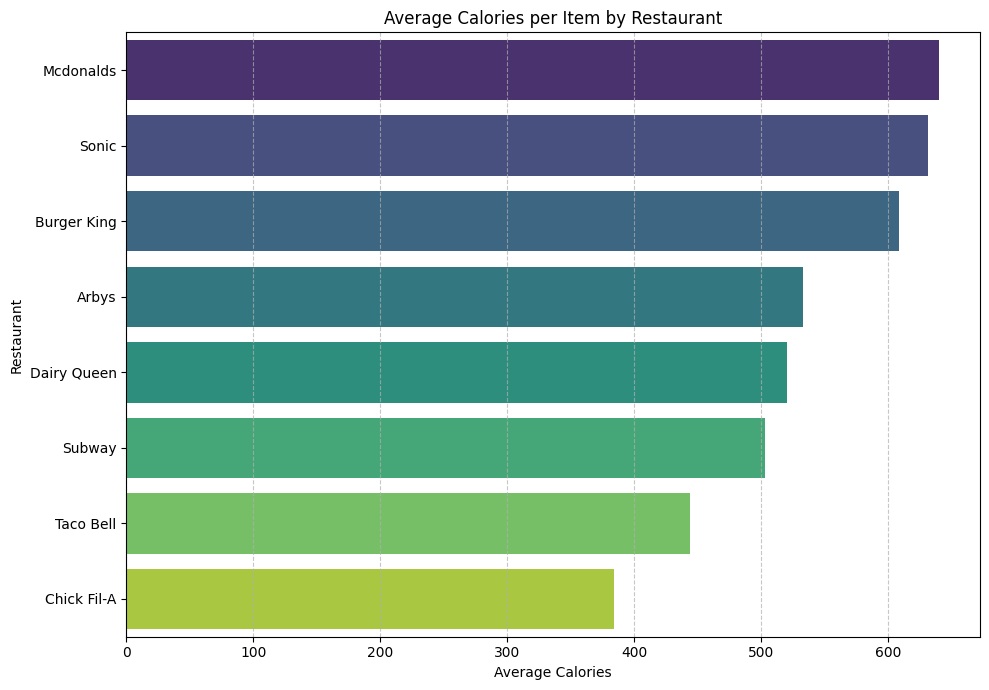

In [ ]:
# Visualize: Horizontal bar chart for average calories by restaurant
fig = plt.figure(figsize=(10, 7))
sns.barplot(x='calories', y='restaurant', data=restaurant_summary.sort_values('calories', ascending=False), palette='viridis')
plt.title('Average Calories per Item by Restaurant')
plt.xlabel('Average Calories')
plt.ylabel('Restaurant')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Nutrient Correlation Analysis

In [ ]:
# Select relevant numerical columns for correlation analysis from the original (unscaled) data
# Exclude 'restaurant', 'item', 'salad' as they are not numerical for direct correlation
# Use df_original to ensure correlations are on actual nutrient values, not scaled ones

# Ensure df_original is available; if not, reload it (assuming it was reloaded for outlier analysis)
if 'df_original' not in locals():
    df_original = pd.read_csv("fastfood.csv")

# Let's re-create a 'clean' df_corr from df_original suitable for correlation analysis
df_corr = df_original.copy()

# Impute missing values in 'fiber' and 'protein' with the mean for correlation analysis
df_corr['fiber'].fillna(df_corr['fiber'].mean(), inplace=True)
df_corr['protein'].fillna(df_corr['protein'].mean(), inplace=True)

# Drop columns that were identified as having too many missing values or not relevant for correlation
df_corr.drop(columns=['vit_a', 'vit_c', 'calcium', 'item', 'salad'], errors='ignore', inplace=True)

# Select only numerical columns for correlation matrix
numerical_cols_for_corr = df_corr.select_dtypes(include=np.number).columns.tolist()

# Calculate the correlation matrix
correlation_matrix = df_corr[numerical_cols_for_corr].corr()

print("\nNutrient Correlation Matrix:")
print(correlation_matrix)



Nutrient Correlation Matrix:
             calories   cal_fat  total_fat   sat_fat  trans_fat  cholesterol  \
calories     1.000000  0.901661   0.900494  0.739664   0.530354     0.762460   
cal_fat      0.901661  1.000000   0.995311  0.852150   0.648422     0.803997   
total_fat    0.900494  0.995311   1.000000  0.846716   0.648821     0.801352   
sat_fat      0.739664  0.852150   0.846716  1.000000   0.812126     0.764030   
trans_fat    0.530354  0.648422   0.648821  0.812126   1.000000     0.680858   
cholesterol  0.762460  0.803997   0.801352  0.764030   0.680858     1.000000   
sodium       0.817855  0.670458   0.669182  0.487456   0.261466     0.596164   
total_carb   0.712701  0.419373   0.422543  0.276534   0.100284     0.238728   
fiber        0.281389  0.031674   0.035299 -0.039817  -0.118700    -0.059645   
sugar        0.437711  0.255485   0.259370  0.234218   0.112651     0.298259   
protein      0.827116  0.714484   0.713592  0.597994   0.474686     0.865997   

         

/tmp/ipykernel_1775/3570112172.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_corr['fiber'].fillna(df_corr['fiber'].mean(), inplace=True)
/tmp/ipykernel_1775/3570112172.py:14: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inpl

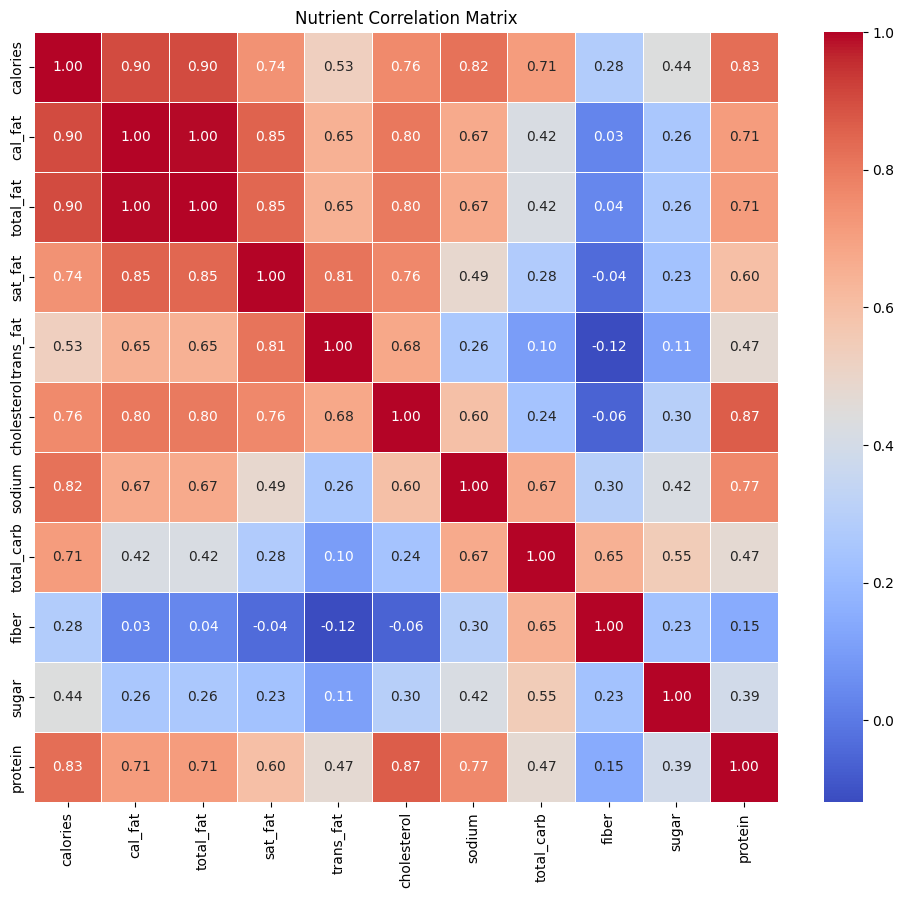

In [ ]:
# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Nutrient Correlation Matrix')
plt.show()


### Nutrient Correlation Analysis

In [ ]:
# Select relevant numerical columns for correlation analysis from the original (unscaled) data
# Exclude 'restaurant', 'item', 'salad' as they are not numerical for direct correlation
# Use df_original to ensure correlations are on actual nutrient values, not scaled ones

# Ensure df_original is available; if not, reload it (assuming it was reloaded for outlier analysis)
if 'df_original' not in locals():
    df_original = pd.read_csv("fastfood.csv")

# Drop the same missing value columns as before to maintain consistency
# For simplicity, we'll re-apply the same missing value handling for this df_original if necessary
# However, given the prior steps, df_original should still be the initial load. Let's make sure.
# For correlation, we should use numerical columns after imputing but *before* scaling.

# Let's re-create a 'clean' df_corr from df_original suitable for correlation analysis
df_corr = df_original.copy()

# Impute missing values in 'fiber' and 'protein' with the mean for correlation analysis
df_corr['fiber'].fillna(df_corr['fiber'].mean(), inplace=True)
df_corr['protein'].fillna(df_corr['protein'].mean(), inplace=True)

# Drop columns that were identified as having too many missing values or not relevant for correlation
df_corr.drop(columns=['vit_a', 'vit_c', 'calcium', 'item', 'salad'], errors='ignore', inplace=True)

# Select only numerical columns for correlation matrix
numerical_cols_for_corr = df_corr.select_dtypes(include=np.number).columns.tolist()

# Calculate the correlation matrix
correlation_matrix = df_corr[numerical_cols_for_corr].corr()

print("\nNutrient Correlation Matrix:")
print(correlation_matrix)



Nutrient Correlation Matrix:
             calories   cal_fat  total_fat   sat_fat  trans_fat  cholesterol  \
calories     1.000000  0.901661   0.900494  0.739664   0.530354     0.762460   
cal_fat      0.901661  1.000000   0.995311  0.852150   0.648422     0.803997   
total_fat    0.900494  0.995311   1.000000  0.846716   0.648821     0.801352   
sat_fat      0.739664  0.852150   0.846716  1.000000   0.812126     0.764030   
trans_fat    0.530354  0.648422   0.648821  0.812126   1.000000     0.680858   
cholesterol  0.762460  0.803997   0.801352  0.764030   0.680858     1.000000   
sodium       0.817855  0.670458   0.669182  0.487456   0.261466     0.596164   
total_carb   0.712701  0.419373   0.422543  0.276534   0.100284     0.238728   
fiber        0.281389  0.031674   0.035299 -0.039817  -0.118700    -0.059645   
sugar        0.437711  0.255485   0.259370  0.234218   0.112651     0.298259   
protein      0.827116  0.714484   0.713592  0.597994   0.474686     0.865997   

         

/tmp/ipykernel_1775/2593897906.py:18: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_corr['fiber'].fillna(df_corr['fiber'].mean(), inplace=True)
/tmp/ipykernel_1775/2593897906.py:19: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inpl

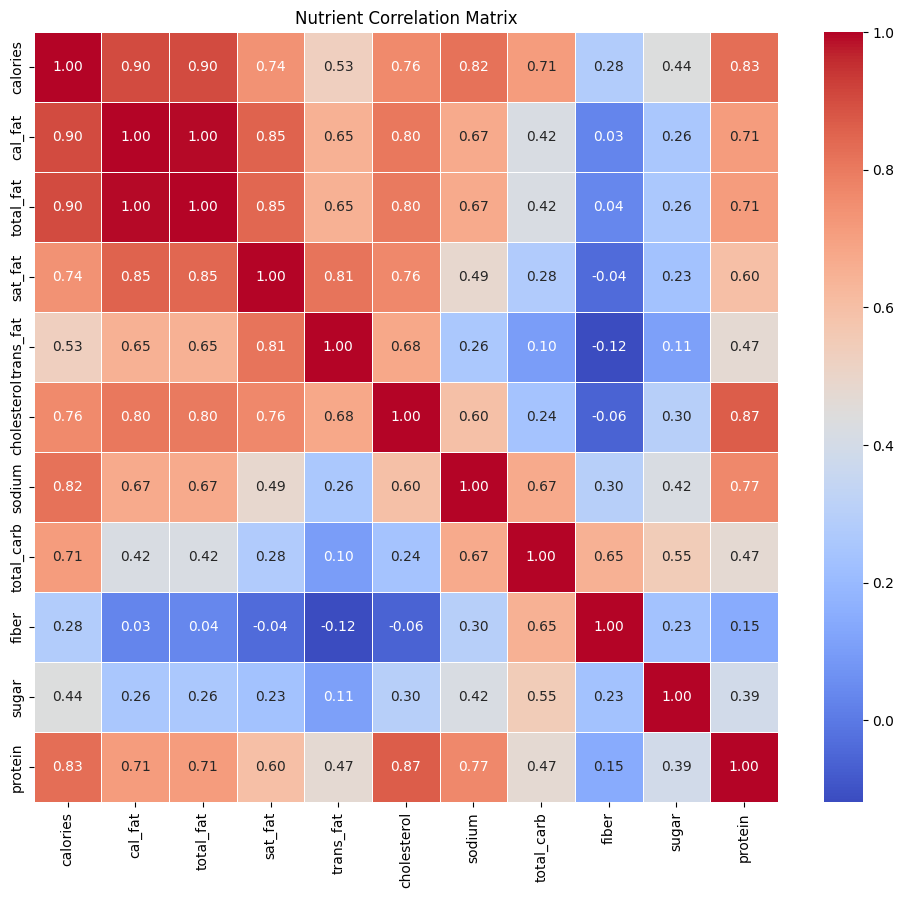

In [ ]:
# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Nutrient Correlation Matrix')
plt.show()


In [ ]:
df['fiber'] = df['fiber'].fillna(df['fiber'].mean())
df['protein'] = df['protein'].fillna(df['protein'].mean())

# Drop 'vit_a', 'vit_c', and 'calcium' columns due to high percentage of missing values
df.drop(columns=['vit_a', 'vit_c', 'calcium'], inplace=True, errors='ignore')

print("\nMissing Values After Cleaning:")
df.isnull().sum()


Missing Values After Cleaning:


,0
calories,0
cal_fat,0
total_fat,0
sat_fat,0
trans_fat,0
cholesterol,0
sodium,0
total_carb,0
fiber,0
sugar,0


### Question 1: Which restaurant has the highest number of food items in the dataset?

In [ ]:
# Group by restaurant and count the number of items
item_counts = df_original['restaurant'].value_counts()

# Get the restaurant with the highest number of items
highest_items_restaurant = item_counts.idxmax()
max_items_count = item_counts.max()

print(f"The restaurant with the highest number of food items is {highest_items_restaurant} with {max_items_count} items.")

The restaurant with the highest number of food items is Taco Bell with 115 items.


### Question 2: Which food items have the highest number of calories? Find the top 10 items.

In [ ]:
# Sort the DataFrame by 'calories' in descending order and get the top 10 items
top_10_high_calorie_items = df_original.sort_values(by='calories', ascending=False).head(10)

print("Top 10 Food Items with the Highest Calories:")
print(top_10_high_calorie_items[['restaurant', 'item', 'calories']].to_string(index=False))

Top 10 Food Items with the Highest Calories:
 restaurant                                             item  calories
  Mcdonalds       20 piece Buttermilk Crispy Chicken Tenders      2430
  Mcdonalds                       40 piece Chicken McNuggets      1770
  Mcdonalds 10 piece Sweet N' Spicy Honey BBQ Glazed Tenders      1600
Burger King                          American Brewhouse King      1550
  Mcdonalds       12 piece Buttermilk Crispy Chicken Tenders      1510
      Sonic Garlic Parmesan Dunked Ultimate Chicken Sandwich      1350
      Sonic   Super Sonic Bacon Double Cheeseburger (w/mayo)      1280
Dairy Queen    6 Piece Chicken Strip Basket w/ Country Gravy      1260
Burger King                                       Rodeo King      1250
Burger King                                   Farmhouse King      1220


### Question 3: What is the average calorie count of food items for each restaurant?

In [ ]:
# Calculate the average calorie count for each restaurant
average_calories_per_restaurant = df_original.groupby('restaurant')['calories'].mean().sort_values(ascending=False)

print("Average Calorie Count per Restaurant:")
print(average_calories_per_restaurant)

Average Calorie Count per Restaurant:
restaurant
Mcdonalds      640.350877
Sonic          631.698113
Burger King    608.571429
Arbys          532.727273
Dairy Queen    520.238095
Subway         503.020833
Taco Bell      443.652174
Chick Fil-A    384.444444
Name: calories, dtype: float64


### Question 4: Which restaurant offers food items with the highest average protein content?

In [ ]:
# Calculate the average protein content for each restaurant
average_protein_per_restaurant = df_original.groupby('restaurant')['protein'].mean().sort_values(ascending=False)

# Get the restaurant with the highest average protein content
highest_protein_restaurant = average_protein_per_restaurant.index[0]
max_protein_content = average_protein_per_restaurant.iloc[0]

print("Average Protein Content per Restaurant:")
print(average_protein_per_restaurant)
print(f"\nThe restaurant with the highest average protein content is {highest_protein_restaurant} with an average of {max_protein_content:.2f}g.")

Average Protein Content per Restaurant:
restaurant
Mcdonalds      40.298246
Chick Fil-A    31.703704
Subway         30.312500
Burger King    30.014493
Arbys          29.254545
Sonic          29.188679
Dairy Queen    24.833333
Taco Bell      17.417391
Name: protein, dtype: float64

The restaurant with the highest average protein content is Mcdonalds with an average of 40.30g.


### Question 5: Which restaurant has the highest average amount of total fat, and which restaurant has the lowest?

In [ ]:
# Calculate the average total fat for each restaurant
average_total_fat_per_restaurant = df_original.groupby('restaurant')['total_fat'].mean().sort_values(ascending=False)

# Get the restaurant with the highest average total fat
highest_fat_restaurant = average_total_fat_per_restaurant.index[0]
max_fat_content = average_total_fat_per_restaurant.iloc[0]

# Get the restaurant with the lowest average total fat
lowest_fat_restaurant = average_total_fat_per_restaurant.index[-1]
min_fat_content = average_total_fat_per_restaurant.iloc[-1]

print("Average Total Fat Content per Restaurant:")
print(average_total_fat_per_restaurant)
print(f"\nThe restaurant with the highest average total fat content is {highest_fat_restaurant} with an average of {max_fat_content:.2f}g.")
print(f"The restaurant with the lowest average total fat content is {lowest_fat_restaurant} with an average of {min_fat_content:.2f}g.")

Average Total Fat Content per Restaurant:
restaurant
Sonic          37.641509
Burger King    36.814286
Mcdonalds      31.807018
Dairy Queen    28.857143
Arbys          26.981818
Taco Bell      20.895652
Subway         18.479167
Chick Fil-A    16.148148
Name: total_fat, dtype: float64

The restaurant with the highest average total fat content is Sonic with an average of 37.64g.
The restaurant with the lowest average total fat content is Chick Fil-A with an average of 16.15g.


### Question 6: Which food items contain the highest amount of sugar, and how many calories do those items contain?

In [ ]:
# Sort the DataFrame by 'sugar' in descending order
highest_sugar_items = df_original.sort_values(by='sugar', ascending=False)

print("Food Items with the Highest Sugar Content and their Calories:")
# Display top 10 items, or you can adjust head(10) to show more or less
print(highest_sugar_items[['restaurant', 'item', 'sugar', 'calories']].head(10).to_string(index=False))

Food Items with the Highest Sugar Content and their Calories:
 restaurant                                                item  sugar  calories
  Mcdonalds    10 piece Sweet N' Spicy Honey BBQ Glazed Tenders     87      1600
  Mcdonalds     6 piece Sweet N' Spicy Honey BBQ Glazed Tenders     52       960
Burger King  Chicken, Apple & Cranberry Salad w/ Crispy Chicken     37       700
     Subway               Footlong Sweet Onion Chicken Teriyaki     36       760
  Mcdonalds     4 piece Sweet N' Spicy Honey BBQ Glazed Tenders     35       640
Burger King Chicken, Apple & Cranberry Salad w/ Grilled Chicken     34       560
Dairy Queen                                  Large Cheese Curds     30      1050
     Subway                         Footlong Corned Beef Reuben     24       940
     Subway                          Footlong Meatball Marinara     24       960
      Arbys                                     Arby-Q Sandwich     23       400


### Question 7: How does the type of food item (salad or other) affect its average calories, fat, carbohydrates, and protein?

In [ ]:
# Group by 'salad' column and calculate the average of specified nutritional metrics
salad_nutrition_summary = df_original.groupby('salad')[['calories', 'total_fat', 'total_carb', 'protein']].mean()

print("Average Nutritional Content by Food Type (Salad vs. Other):")
print(salad_nutrition_summary)

Average Nutritional Content by Food Type (Salad vs. Other):
         calories  total_fat  total_carb    protein
salad                                              
Other  530.912621  26.590291   45.664078  27.891051


### Question 8: Which restaurant offers the best combination of low calories and high protein?

In [ ]:
# Calculate the average calories and protein for each restaurant
restaurant_avg_nutrition = df_original.groupby('restaurant')[['calories', 'protein']].mean().reset_index()

# To find the 'best' combination of low calories and high protein, we need a scoring system.
# A simple approach is to rank by calories (ascending) and by protein (descending)
# and then combine these ranks.

restaurant_avg_nutrition['calorie_rank'] = restaurant_avg_nutrition['calories'].rank(ascending=True)
restaurant_avg_nutrition['protein_rank'] = restaurant_avg_nutrition['protein'].rank(ascending=False)

# A lower combined rank score means a better combination (lower calories + higher protein)
restaurant_avg_nutrition['combined_rank_score'] = restaurant_avg_nutrition['calorie_rank'] + restaurant_avg_nutrition['protein_rank']

# Sort by the combined rank score to find the best restaurant
best_restaurant = restaurant_avg_nutrition.sort_values(by='combined_rank_score', ascending=True).iloc[0]

print("Restaurant Nutritional Averages and Ranks:")
print(restaurant_avg_nutrition.sort_values(by='combined_rank_score').to_string(index=False))

print(f"\nThe restaurant offering the best combination of low calories and high protein is {best_restaurant['restaurant']}.")
print(f"  Average Calories: {best_restaurant['calories']:.2f}")
print(f"  Average Protein: {best_restaurant['protein']:.2f}g")

Restaurant Nutritional Averages and Ranks:
 restaurant   calories   protein  calorie_rank  protein_rank  combined_rank_score
Chick Fil-A 384.444444 31.703704           1.0           2.0                  3.0
     Subway 503.020833 30.312500           3.0           3.0                  6.0
  Mcdonalds 640.350877 40.298246           8.0           1.0                  9.0
      Arbys 532.727273 29.254545           5.0           5.0                 10.0
  Taco Bell 443.652174 17.417391           2.0           8.0                 10.0
Burger King 608.571429 30.014493           6.0           4.0                 10.0
Dairy Queen 520.238095 24.833333           4.0           7.0                 11.0
      Sonic 631.698113 29.188679           7.0           6.0                 13.0

The restaurant offering the best combination of low calories and high protein is Chick Fil-A.
  Average Calories: 384.44
  Average Protein: 31.70g


### Question 9: Identify the 10 least healthy food items by creating a Health Risk Score.

In [ ]:
# To identify the least healthy food items, we will create a 'Health Risk Score'.
# A higher score will indicate less healthy. We'll consider calories, total_fat, sat_fat, trans_fat, cholesterol, sodium, and sugar.
# Protein and fiber are generally considered beneficial, so their contribution to the score should be inverse.

# Ensure df_original is available; if not, reload it
if 'df_original' not in locals():
    df_original = pd.read_csv("fastfood.csv")

df_health_score = df_original.copy()

# Impute missing values for fiber and protein before calculating scores
df_health_score['fiber'] = df_health_score['fiber'].fillna(df_health_score['fiber'].mean())
df_health_score['protein'] = df_health_score['protein'].fillna(df_health_score['protein'].mean())

# Define the 'unhealthy' nutrients (higher is worse)
unhealthy_metrics = ['calories', 'total_fat', 'sat_fat', 'trans_fat', 'cholesterol', 'sodium', 'sugar']
# Define the 'healthy' nutrients (higher is better)
healthy_metrics = ['protein', 'fiber']

# We'll use a simple approach: sum normalized unhealthy metrics and subtract normalized healthy metrics.
# First, scale all relevant columns to a 0-1 range to ensure fair contribution.
# We will only scale the columns involved in the health score to avoid modifying other data unnecessarily.

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# Apply scaling to unhealthy metrics
df_health_score[unhealthy_metrics] = scaler.fit_transform(df_health_score[unhealthy_metrics])

# Apply scaling to healthy metrics
df_health_score[healthy_metrics] = scaler.fit_transform(df_health_score[healthy_metrics])

# Calculate Health Risk Score:
# Sum of scaled unhealthy metrics - Sum of scaled healthy metrics

df_health_score['health_risk_score'] = df_health_score[unhealthy_metrics].sum(axis=1) - df_health_score[healthy_metrics].sum(axis=1)

# Sort by health_risk_score in descending order to find the least healthy items
least_healthy_items = df_health_score.sort_values(by='health_risk_score', ascending=False).head(10)

print("Top 10 Least Healthy Food Items (by Health Risk Score):")
print(least_healthy_items[['restaurant', 'item', 'calories', 'total_fat', 'protein', 'health_risk_score']].to_string(index=False))

Top 10 Least Healthy Food Items (by Health Risk Score):
 restaurant                                             item  calories  total_fat  protein  health_risk_score
Burger King                          American Brewhouse King  0.634855   0.893617 0.718919           4.011151
  Mcdonalds       20 piece Buttermilk Crispy Chicken Tenders  1.000000   1.000000 1.000000           3.267536
Dairy Queen                               Large Cheese Curds  0.427386   0.531915 0.227027           2.702510
      Sonic   Super Sonic Bacon Double Cheeseburger (w/mayo)  0.522822   0.652482 0.356757           2.636581
  Mcdonalds 10 piece Sweet N' Spicy Honey BBQ Glazed Tenders  0.655602   0.468085 0.518919           2.583854
Burger King                                   Farmhouse King  0.497925   0.567376 0.145357           2.571420
      Sonic          Super Sonic Double Cheeseburger W/ Mayo  0.497925   0.617021 0.335135           2.530016
Burger King                                       Rodeo King  0.

### Question 10: Compare nutritional profiles of all restaurants and determine the healthiest overall menu using a custom scoring system.

In [ ]:
# To determine the healthiest overall menu, we'll use the 'health_risk_score' calculated for individual items.
# The healthiest restaurant will be the one with the lowest average health risk score across all its menu items.

# Ensure df_original is available and has 'health_risk_score' from the previous step
# If df_health_score from Question 9 is not available, we need to re-create it.
if 'df_health_score' not in locals():
    # Reload df_original if necessary
    if 'df_original' not in locals():
        df_original = pd.read_csv("fastfood.csv")

    df_health_score = df_original.copy()

    # Impute missing values for fiber and protein
    df_health_score['fiber'] = df_health_score['fiber'].fillna(df_health_score['fiber'].mean())
    df_health_score['protein'] = df_health_score['protein'].fillna(df_health_score['protein'].mean())

    # Define and scale metrics (as done in Q9)
    from sklearn.preprocessing import MinMaxScaler
    scaler = MinMaxScaler()
    unhealthy_metrics = ['calories', 'total_fat', 'sat_fat', 'trans_fat', 'cholesterol', 'sodium', 'sugar']
    healthy_metrics = ['protein', 'fiber']
    df_health_score[unhealthy_metrics] = scaler.fit_transform(df_health_score[unhealthy_metrics])
    df_health_score[healthy_metrics] = scaler.fit_transform(df_health_score[healthy_metrics])

    # Calculate Health Risk Score
    df_health_score['health_risk_score'] = df_health_score[unhealthy_metrics].sum(axis=1) - df_health_score[healthy_metrics].sum(axis=1)

# Group by restaurant and calculate the average health risk score
restaurant_health_scores = df_health_score.groupby('restaurant')['health_risk_score'].mean().sort_values(ascending=True)

# Identify the restaurant with the lowest average health risk score
healthiest_restaurant = restaurant_health_scores.index[0]
min_health_score = restaurant_health_scores.iloc[0]

print("Average Health Risk Score per Restaurant (Lower is Healthier):")
print(restaurant_health_scores)
print(f"\nThe restaurant with the healthiest overall menu is {healthiest_restaurant} with an average health risk score of {min_health_score:.2f}.")

Average Health Risk Score per Restaurant (Lower is Healthier):
restaurant
Taco Bell      0.327268
Subway         0.345807
Chick Fil-A    0.380785
Arbys          0.735755
Dairy Queen    0.778022
Mcdonalds      0.813335
Burger King    0.957626
Sonic          0.974862
Name: health_risk_score, dtype: float64

The restaurant with the healthiest overall menu is Taco Bell with an average health risk score of 0.33.
